
# Thí nghiệm 01 — Trực quan hóa kết quả dự báo hệ Lorenz

## Mục tiêu

Notebook này tập hợp mã nguồn trực quan hóa và các hình minh họa chính của thí nghiệm dự báo chuỗi thời gian Lorenz bằng các mô hình kết hợp toán tử Koopman.

Các hình được lựa chọn nhằm đối chiếu với nội dung thực nghiệm Lorenz trong bài báo DeepKoopFormer.

Notebook tập trung vào hai nội dung:

1. So sánh kết quả dự báo của ba biến thể mô hình trên các biến trạng thái của hệ Lorenz.
2. Phân tích sự thay đổi của chỉ số ổn định toán tử Koopman trong quá trình huấn luyện.

## Các mô hình được so sánh

Ba biến thể được sử dụng gồm:

- **PatchTST + Koopman:** sử dụng backbone dựa trên PatchTST.
- **Autoformer + Koopman:** sử dụng backbone dựa trên Autoformer.
- **Informer + Koopman:** sử dụng backbone dựa trên Informer.

Cả ba mô hình đều sử dụng toán tử Koopman có ràng buộc ổn định trong không gian tiềm ẩn.

Chi tiết kiến trúc được trình bày tại `02_lorenz_model.ipynb`.

## Nguồn dữ liệu và kết quả

Các hình được xây dựng dựa trên:

- Bộ dữ liệu đã lưu tại `results/lorenz_dataset.pt`.
- Trọng số của các mô hình đã hoàn thành huấn luyện.
- Lịch sử giá trị kỳ dị được lưu trong các checkpoint.

Mã nguồn dựng hình được tách từ `03_lorenz_training.ipynb` nhằm phân biệt quá trình huấn luyện với quá trình trực quan hóa kết quả.

## Nguyên tắc bảo toàn thực nghiệm

Trong quá trình tái cấu trúc repository:

- Không tạo lại dữ liệu Lorenz.
- Không huấn luyện lại bất kỳ mô hình nào.
- Không thay đổi hoặc ghi đè trọng số đã lưu.
- Không tính toán lại kết quả chỉ để thay đổi cách trình bày.
- Giữ lại các hình đã được tạo từ thực nghiệm trước đó.

Các hình PNG đã xuất được lưu trong thư mục `figures/`, giúp xem và sử dụng trực tiếp trong báo cáo mà không cần thực thi notebook.

## Phạm vi trực quan hóa

Notebook chỉ giữ hai hình chính tương ứng về nội dung với phần thực nghiệm Lorenz của bài báo gốc.

Các biểu đồ phụ như training loss riêng từng mô hình, quỹ đạo Lorenz 3D và các biểu đồ kiểm tra riêng lẻ không được đưa vào danh mục hình chính phục vụ báo cáo.


In [2]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

# Xác định thư mục thí nghiệm
cwd = Path.cwd()

if (cwd / "experiments" / "01_lorenz").is_dir():
    experiment_dir = cwd / "experiments" / "01_lorenz"
elif cwd.name == "01_lorenz":
    experiment_dir = cwd
else:
    raise FileNotFoundError("Không tìm thấy thư mục thí nghiệm Lorenz")

# Xác định thiết bị sử dụng khi suy luận
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Nạp định nghĩa kiến trúc đã có
model_path = experiment_dir / "02_lorenz_model.ipynb"

get_ipython().run_line_magic(
    "run",
    f'"{model_path.as_posix()}"'
)

# Đọc dữ liệu đã lưu, không sinh dữ liệu mới
dataset = torch.load(
    experiment_dir / "results" / "lorenz_dataset.pt",
    map_location="cpu"
)

x_in = dataset["X"].to(device)
x_out = dataset["Y"].to(device)

patch_length = dataset["patch_length"]
horizon = dataset["horizon"]


## 1. So sánh kết quả dự báo trên hệ Lorenz

### 1.1. Mục đích

Hình đầu tiên được sử dụng để so sánh khả năng dự báo chuỗi thời gian của ba biến thể mô hình:

- PatchTST kết hợp Koopman.
- Autoformer kết hợp Koopman.
- Informer kết hợp Koopman.

Đối tượng dự báo là hệ Lorenz có ba biến trạng thái $x_1$, $x_2$ và $x_3$.

Mục tiêu của hình là quan sát mức độ tương đồng giữa giá trị dự báo của từng mô hình và dữ liệu thực tế.

### 1.2. Phương pháp trực quan hóa

Các mô hình được nạp từ checkpoint đã lưu sau quá trình huấn luyện.

Dữ liệu đầu vào gồm các cửa sổ có độ dài 150 bước thời gian, với chân trời dự báo bằng 5.

Trong mã nguồn dựng hình hiện tại, giá trị dự báo tại bước đầu tiên của mỗi cửa sổ được sử dụng để biểu diễn chuỗi kết quả.

Ba biểu đồ con lần lượt tương ứng với:

- Biến trạng thái $x_1$.
- Biến trạng thái $x_2$.
- Biến trạng thái $x_3$.

Mỗi biểu đồ gồm bốn đường:

| Đường biểu diễn | Ý nghĩa |
|---|---|
| Ground Truth | Giá trị thực tế |
| PatchTST | Giá trị dự báo từ PatchTST + Koopman |
| Autoformer | Giá trị dự báo từ Autoformer + Koopman |
| Informer | Giá trị dự báo từ Informer + Koopman |

### 1.3. Kết quả trực quan hóa

![So sánh dự báo ba biến trạng thái của hệ Lorenz](figures/lorenz_forecasting_comparison.png)

**Hình 1.** So sánh giá trị dự báo của ba biến thể mô hình với dữ liệu thực tế trên ba biến trạng thái của hệ Lorenz.

### 1.4. Nhận xét kết quả

Quan sát hình cho thấy các mô hình có khả năng mô phỏng xu hướng biến thiên của ba biến trạng thái Lorenz ở những mức độ khác nhau.

Đường dự báo của PatchTST và Informer nhìn chung bám sát đường giá trị thực tế trong phần lớn khoảng thời gian được biểu diễn.

Đối với Autoformer, đường dự báo xuất hiện những sai lệch rõ rệt hơn, đặc biệt tại một số thời điểm có biến thiên mạnh.

Những quan sát này phù hợp với bảng in-sample MSE được tổng hợp trong `04_lorenz_results.ipynb`, trong đó PatchTST có sai số nhỏ nhất và Autoformer có sai số lớn nhất.

### 1.5. Đối chiếu với bài báo gốc

Hình này tương ứng về mục đích với Figure 1 trong phần thực nghiệm Lorenz của bài báo DeepKoopFormer.

Cả hai đều hướng đến việc so sánh kết quả dự báo của các biến thể mô hình trên các biến trạng thái của hệ Lorenz.

Tuy nhiên, mã nguồn của thí nghiệm hiện tại sử dụng bước dự báo đầu tiên từ mỗi cửa sổ để dựng hình.

Vì vậy, không mặc nhiên coi đây là bản tái lập hoàn toàn giống hình gốc về cách lựa chọn và ghép các dự báo nhiều bước.

### 1.6. Giới hạn đánh giá

Hình được dựng từ các mẫu thuộc bộ dữ liệu đã sử dụng trong quá trình huấn luyện.

Do đó, các kết quả trực quan hóa thể hiện mức độ khớp của mô hình trên dữ liệu huấn luyện, chưa phản ánh trực tiếp khả năng tổng quát hóa trên tập kiểm tra độc lập.


PatchTST In-Sample MSE: 0.281637
Autoformer In-Sample MSE: 12.407234
Informer In-Sample MSE: 1.451354


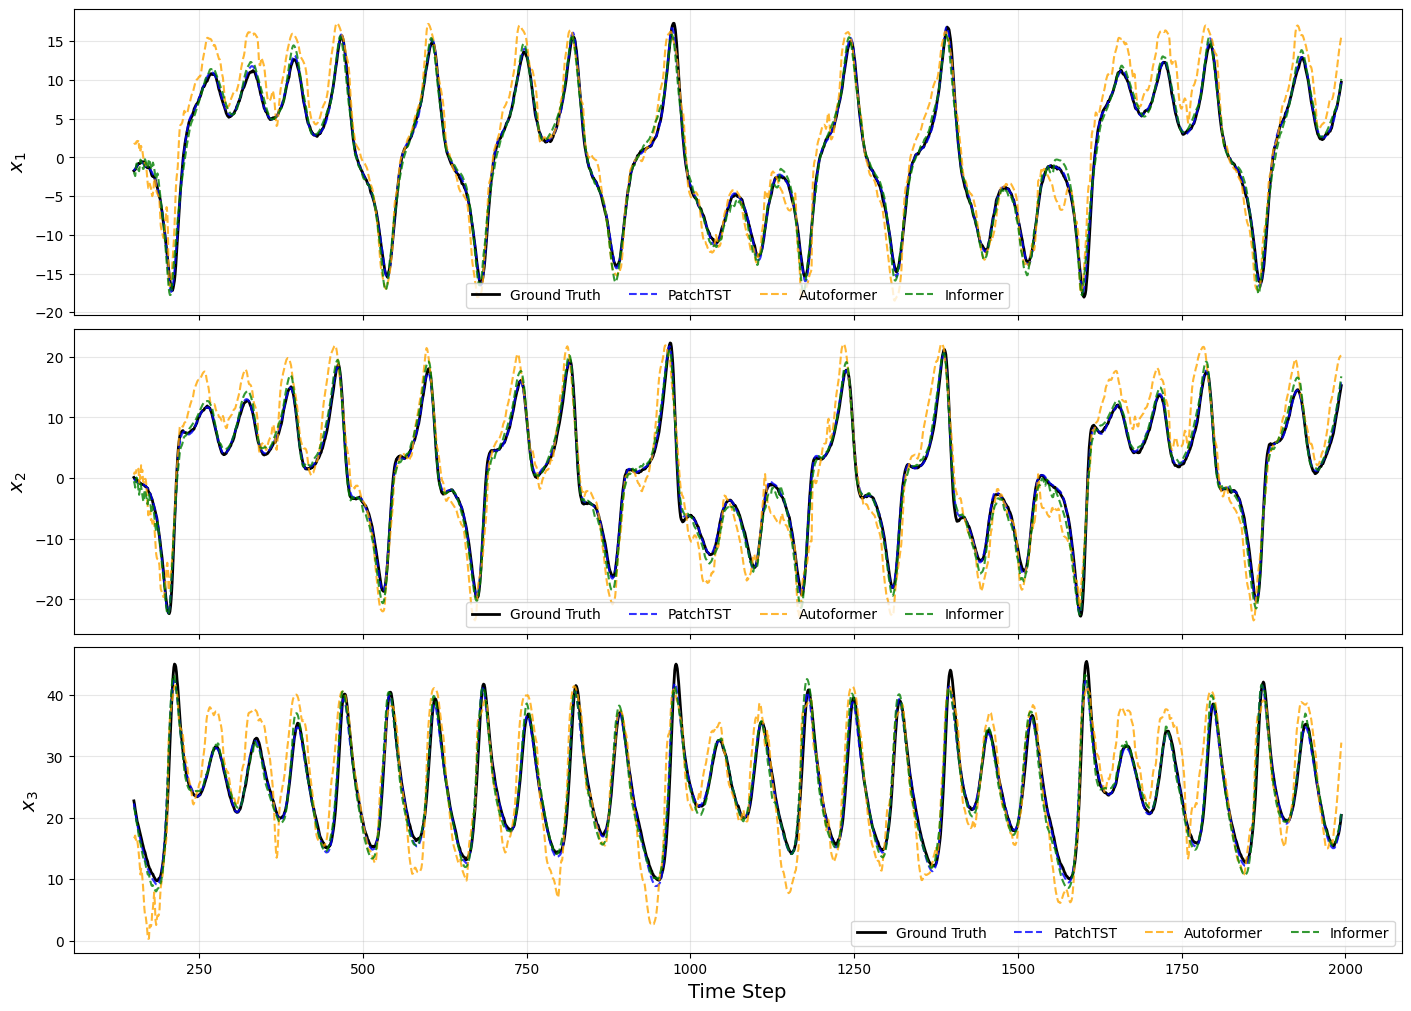

In [3]:
# 1. Load checkpoints
checkpoint_paths = {
    "PatchTST": experiment_dir / "results" / "patchtst_original_fullbatch.pt",
    "Autoformer": experiment_dir / "results" / "autoformer_original_fullbatch.pt",
    "Informer": experiment_dir / "results" / "informer_original_fullbatch.pt"
}

models = {
    "PatchTST": PatchTSTWrapper(patch_length, horizon).to(device),
    "Autoformer": AutoformerWrapper(patch_length, horizon).to(device),
    "Informer": InformerWrapper(patch_length, horizon).to(device)
}

results = {}

# 2. Load models and evaluate
for name, model in models.items():
    checkpoint = torch.load(
        checkpoint_paths[name],
        map_location="cpu"
    )

    if name == "Autoformer":
        assert checkpoint.get("batch_size") == len(x_in), (
            "Checkpoint Autoformer không phải bản Full-batch trực tiếp"
        )

    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    predictions = []

    with torch.no_grad():
        for start in range(0, len(x_in), 64):
            preds, _, _, _, _ = model(x_in[start:start + 64])
            predictions.append(preds.cpu())

    predictions = torch.cat(predictions, dim=0).numpy()
    results[name] = predictions

    mse_value = np.mean(
        (predictions - x_out.cpu().numpy()) ** 2
    )

    print(f"{name} In-Sample MSE: {mse_value:.6f}")

# 3. Plot predictions
true_vals = x_out.cpu().numpy()

num_points = len(x_in)
time_steps = np.arange(num_points) + patch_length
var_labels = [r"$x_1$", r"$x_2$", r"$x_3$"]

colors = {
    "PatchTST": "blue",
    "Autoformer": "orange",
    "Informer": "green"
}

fig, axes = plt.subplots(
    3, 1, figsize=(14, 10),
    sharex=True,
    constrained_layout=True
)

for idx, ax in enumerate(axes):

    ax.plot(
        time_steps,
        true_vals[:num_points, idx],
        color="black",
        linewidth=2,
        label="Ground Truth"
    )

    for name, preds in results.items():
        ax.plot(
            time_steps,
            preds[:num_points, idx],
            "--",
            color=colors[name],
            linewidth=1.5,
            alpha=0.8,
            label=name
        )

    ax.set_ylabel(var_labels[idx], fontsize=14)
    ax.grid(True, alpha=0.3)
    ax.legend(ncol=4, fontsize=10)

axes[-1].set_xlabel("Time Step", fontsize=14)

plt.show()



## 2. Phân tích sự thay đổi độ ổn định của toán tử Koopman

### 2.1. Mục đích

Bên cạnh sai số dự báo, thí nghiệm còn quan tâm đến tính ổn định của quá trình biến đổi trạng thái trong không gian tiềm ẩn.

Toán tử Koopman được xây dựng nhằm mô hình hóa sự tiến hóa của biểu diễn tiềm ẩn thông qua một phép biến đổi tuyến tính.

Gọi $\mathbf{z}_t$ là trạng thái tiềm ẩn tại thời điểm $t$, ta xét:

$$
\mathbf{z}_{t+1}=K\mathbf{z}_t
$$

Trong đó $K$ là ma trận toán tử Koopman.

Mục tiêu trực quan hóa là theo dõi sự thay đổi của chỉ số ổn định trong quá trình huấn luyện ba biến thể mô hình.

### 2.2. Cấu trúc toán tử Koopman

Trong mã nguồn, toán tử Koopman được xây dựng theo dạng:

$$
K=U\operatorname{diag}(s)V^\top
$$

Trong đó:

- $U$ và $V$ là hai ma trận trực giao.
- $s$ là vector các giá trị được khống chế.
- $\operatorname{diag}(s)$ là ma trận đường chéo tương ứng.

Các giá trị $s_i$ được xác định bởi:

$$
s_i=0.99\cdot\operatorname{sigmoid}(a_i)
$$

Do đó:

$$
0<s_i<0.99
$$

Cấu trúc này tạo ra một ràng buộc đối với chuẩn phổ của toán tử Koopman.

### 2.3. Phương pháp trực quan hóa

Trong quá trình huấn luyện, các giá trị kỳ dị của toán tử Koopman được ghi nhận định kỳ.

Notebook đọc lại các lịch sử này từ checkpoint đã lưu.

Với mỗi lần ghi nhận, giá trị kỳ dị lớn nhất được xác định bởi:

$$
\sigma_{\max}(K)=\max_i \sigma_i(K)
$$

Biểu đồ gồm:

- Trục hoành: số epoch huấn luyện.
- Trục tung: giá trị kỳ dị lớn nhất.
- Ba đường biểu diễn tương ứng với PatchTST, Autoformer và Informer.
- Đường tham chiếu thể hiện giới hạn 0.99.

### 2.4. Kết quả trực quan hóa

![Sự thay đổi giá trị kỳ dị lớn nhất của toán tử Koopman](figures/lorenz_koopman_stability.png)

**Hình 2.** Sự thay đổi giá trị kỳ dị lớn nhất của toán tử Koopman trong quá trình huấn luyện ba biến thể mô hình.

### 2.5. Kết quả sau huấn luyện

| Mô hình | Giá trị kỳ dị lớn nhất |
|---|---:|
| PatchTST + Koopman | 0.917746 |
| Autoformer + Koopman | 0.892004 |
| Informer + Koopman | 0.961025 |

Các giá trị trên được trích từ checkpoint sau khi hoàn thành 3.000 epoch.

Cả ba giá trị đều nhỏ hơn giới hạn 0.99.

### 2.6. Nhận xét

Biểu đồ cho thấy giá trị kỳ dị lớn nhất của toán tử Koopman thay đổi trong quá trình huấn luyện nhưng vẫn nằm dưới ngưỡng đã thiết lập.

Trong ba mô hình:

- Autoformer có giá trị kỳ dị lớn nhất cuối cùng thấp nhất.
- Informer có giá trị kỳ dị lớn nhất cuối cùng cao nhất.
- PatchTST có giá trị nằm giữa hai mô hình còn lại.

Kết quả phù hợp với cấu trúc toán tử Koopman có ràng buộc chuẩn phổ.

Tuy nhiên, giá trị kỳ dị lớn nhất thấp hơn không đồng nghĩa với chất lượng dự báo tốt hơn.

### 2.7. Phân biệt giá trị kỳ dị lớn nhất và bán kính phổ

Đối với một ma trận $K$, bán kính phổ được xác định bởi:

$$
\rho(K)=\max_i|\lambda_i(K)|
$$

Trong khi đó, chuẩn phổ tương ứng với giá trị kỳ dị lớn nhất:

$$
\|K\|_2=\sigma_{\max}(K)
$$

Hai đại lượng thỏa mãn:

$$
\rho(K)\leq\|K\|_2
$$

Vì vậy, khi giá trị kỳ dị lớn nhất nhỏ hơn 0.99, bán kính phổ cũng được khống chế dưới ngưỡng này.

Tuy nhiên, giá trị kỳ dị lớn nhất và bán kính phổ không phải cùng một đại lượng.

### 2.8. Đối chiếu với bài báo gốc

Hình này tương ứng về mục đích với Figure 2 trong phần thực nghiệm Lorenz của bài báo DeepKoopFormer.

Tuy nhiên, hình của repository theo dõi giá trị kỳ dị lớn nhất, trong khi hình của tác giả được mô tả thông qua trị riêng lớn nhất hoặc bán kính phổ.

Vì vậy, đây là hình đánh giá ràng buộc ổn định theo chuẩn phổ, không phải bản dựng lại trực tiếp đường biến thiên bán kính phổ của tác giả.

Sự khác biệt này cần được nêu rõ khi trình bày kết quả tái lập.


PatchTST: Final Max Singular Value = 0.917746
Autoformer: Final Max Singular Value = 0.892004
Informer: Final Max Singular Value = 0.961025


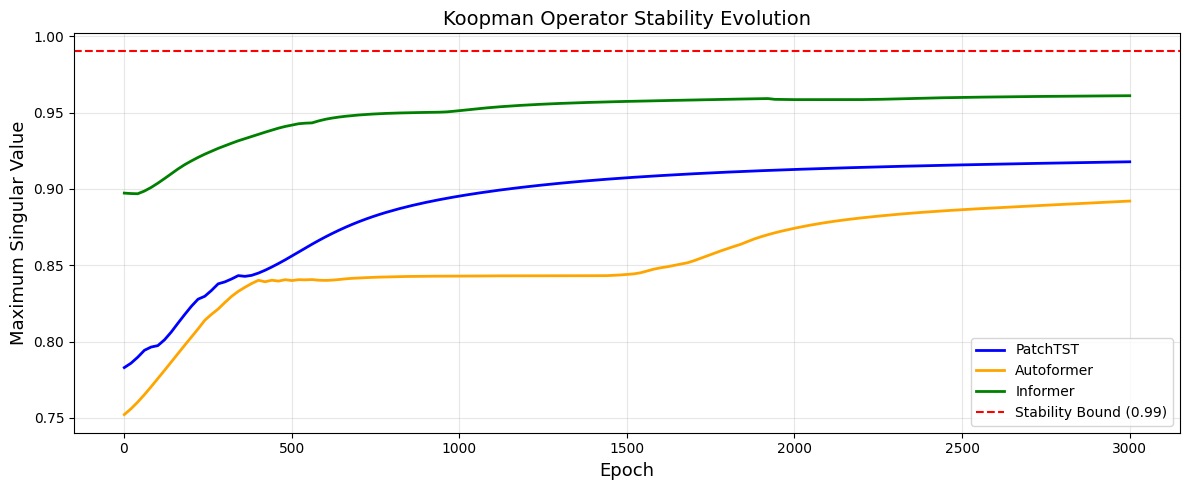

In [4]:

# Trực quan hóa sự thay đổi giá trị kỳ dị lớn nhất
# của toán tử Koopman trong quá trình huấn luyện
colors = {
    "PatchTST": "blue",
    "Autoformer": "orange",
    "Informer": "green"
}

plt.figure(figsize=(12, 5))

# 1. Load singular value histories
for name, path in checkpoint_paths.items():

    checkpoint = torch.load(path, map_location="cpu")

    singular_history = np.asarray(
        checkpoint["singular_history"]
    )

    singular_epochs = np.asarray(
        checkpoint["singular_epochs"]
    )

    max_singular = singular_history.max(axis=1)

    # Giá trị kỳ dị cuối cùng sau epoch 3000
    final_singular = (
        torch.sigmoid(
            checkpoint["model_state_dict"]["koopman.S_unconstrained"]
        ) * 0.99
    ).max().item()

    plot_epochs = np.append(singular_epochs, 3000)
    plot_values = np.append(max_singular, final_singular)

    plt.plot(
        plot_epochs,
        plot_values,
        label=name,
        color=colors[name],
        linewidth=2
    )

    print(
        f"{name}: Final Max Singular Value = "
        f"{final_singular:.6f}"
    )

# 2. Stability bound
plt.axhline(
    y=0.99,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label="Stability Bound (0.99)"
)

# 3. Plot
plt.xlabel("Epoch", fontsize=13)
plt.ylabel("Maximum Singular Value", fontsize=13)
plt.title("Koopman Operator Stability Evolution", fontsize=14)

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



## 3. Tổng kết kết quả trực quan hóa

Notebook đã tập hợp hai hình chính của thí nghiệm Lorenz:

1. So sánh kết quả dự báo của ba biến thể mô hình trên các biến trạng thái $x_1$, $x_2$, $x_3$.
2. Phân tích sự thay đổi giá trị kỳ dị lớn nhất của toán tử Koopman trong quá trình huấn luyện.

### 3.1. Danh mục hình ảnh

| Hình | Tệp hình ảnh | Nội dung |
|---|---|---|
| Hình 1 | `lorenz_forecasting_comparison.png` | So sánh kết quả dự báo Lorenz |
| Hình 2 | `lorenz_koopman_stability.png` | Sự thay đổi độ ổn định của toán tử Koopman |

Các tệp hình được lưu tại:

`experiments/01_lorenz/figures/`

### 3.2. Liên kết với các notebook khác

| Notebook | Vai trò |
|---|---|
| `01_lorenz_data.ipynb` | Chuẩn bị bộ dữ liệu Lorenz |
| `02_lorenz_model.ipynb` | Định nghĩa các kiến trúc mô hình |
| `03_lorenz_training.ipynb` | Huấn luyện và lưu checkpoint |
| `04_lorenz_results.ipynb` | Tổng hợp bảng số liệu và phân tích |
| `05_lorenz_figures.ipynb` | Trực quan hóa các kết quả chính |

### 3.3. Nguyên tắc sử dụng hình trong báo cáo

Các hình đã lưu được sử dụng trực tiếp khi trình bày kết quả thực nghiệm.

Khi sử dụng, cần:

- Giữ nguyên nội dung hình đã tạo từ thực nghiệm.
- Ghi rõ đại lượng được biểu diễn.
- Phân biệt kết quả trên dữ liệu huấn luyện với kết quả trên dữ liệu kiểm tra.
- Nêu rõ những khác biệt giữa cách triển khai trong repository và phương pháp mô tả trong bài báo gốc.
- Không thay đổi dữ liệu hoặc đường biểu diễn nhằm làm cho kết quả giống với bài báo.

### 3.4. Kết luận

Các hình trực quan hóa giúp quan sát hai khía cạnh của thí nghiệm: chất lượng dự báo trên dữ liệu Lorenz và đặc điểm ổn định của toán tử Koopman.

Kết quả dự báo cho thấy sự khác biệt giữa các backbone được sử dụng, trong khi biểu đồ giá trị kỳ dị cho thấy cả ba toán tử Koopman đều thỏa mãn ràng buộc chuẩn phổ trong các giá trị đã ghi nhận.

Những nhận xét này được giới hạn trong phạm vi cấu hình và dữ liệu đã thực nghiệm, không được mở rộng thành kết luận về khả năng tổng quát hóa khi chưa có đánh giá độc lập.
